In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/kellyloveskelp/eds220-hwk2.git


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

<Axes: title={'center': 'Mean Catch by Region from 1878-1997'}, xlabel='Regions', ylabel='Average Catch'>

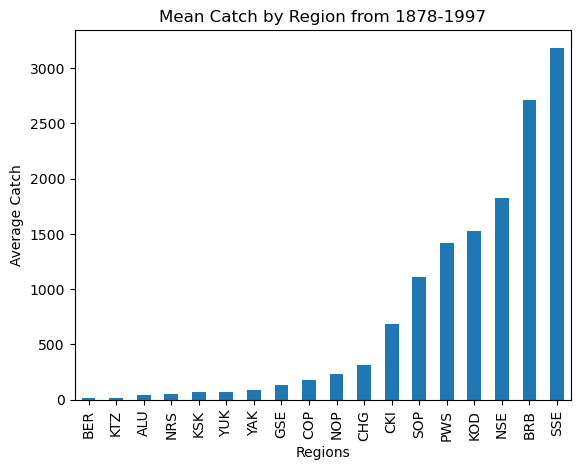

In [ ]:
# FINAL CODE
import pandas as pd
import numpy as np

catch_data = pd.read_csv(
    'task2/data/salmon_data.csv').drop(
        columns = "notesRegCode")

catch_data.iloc[400, 3] = 1
catch_data['Catch'] = catch_data['Catch'].astype('int64')
catch_data.groupby('Region')['Catch'].mean(
    ).sort_values(
    ).plot(
        kind='bar',
        title='Mean Catch by Region from 1878-1997',
        xlabel='Regions',
        ylabel='Average Catch')


## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [129]:
# a.
import pandas as pd
import numpy as np

catch_data = pd.read_csv('/Users/kellyanne/Desktop/meds2027/eds220/eds220-hwk2/task2/data/salmon_data.csv')
# read_csv() function could not find file without full path
catch_data.head()


,Region,Year,notesRegCode,Species,Catch
0,SSE,1886,NaN,Chinook,0
1,SSE,1887,NaN,Chinook,0
2,SSE,1888,NaN,Chinook,0
3,SSE,1889,NaN,Chinook,0
4,SSE,1890,NaN,Chinook,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [130]:
# b.
# How many unqiue values are there in each column?
print(catch_data.nunique())

# How many unique species are recorded?
print("Species:", catch_data['Species'].unique())

# How des dropping the NAs affect the sizze of the dataset?
print(catch_data['notesRegCode'].shape, "vs",catch_data['notesRegCode'].dropna().shape)
8540-1415

Region            18
Year             120
notesRegCode      29
Species            5
Catch           1879
dtype: int64
Species: ['Chinook' 'Sockeye' 'Coho' 'Pink' 'Chum']
(8540,) vs (1415,)


7125

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

First, I used nunique() to see how many unique values there are for each column and get an idea the variability between each column type.

Then, I specificaly called unique() on the "Species" column to see how many different species are recorded in the dataset.

After noticing there are a lot of missing values in the "notesRegCode", I compared the size of that column before and after applying the dropna() function. It showed me there are 7125 missing values in the "notesRegCode" column alone!

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [131]:
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [132]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [133]:
catch_data = catch_data.drop(columns = "notesRegCode") # Tell .drop() to drop the "notesRegCode" column

In [134]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


_No; I would have expected "Catch" to be an integer data type, rather than an object type._

In [135]:
# Check data type for each column in dataset:
print(catch_data.dtypes)

# What does the data in "Catch" look like?
catch_data['Catch'].unique()

Region     object
Year        int64
Species    object
Catch      object
dtype: object


array(['0', '3', '4', ..., '709', '667', '393'], dtype=object)

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [136]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [137]:
catch_I = catch_data[catch_data['Catch'] == "I"]
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [138]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [139]:
catch_data.iloc[400, 3] = 1

catch_1 = catch_data.iloc[400, ]

# Print catch_1
catch_1

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [146]:
catch_data['Catch'] = catch_data['Catch'].astype('int64')
catch_column_type = catch_data['Catch'].dtype
catch_column_type 

dtype('int64')

In [147]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [164]:
avg_region = catch_data.groupby('Region')['Catch'].mean()
avg_region

Region
ALU      40.383908
BER      16.372549
BRB    2709.796491
CHG     315.487273
CKI     683.571429
COP     179.223404
GSE     133.841463
KOD    1528.350000
KSK      67.642353
KTZ      18.836145
NOP     229.493478
NRS      51.502703
NSE    1825.020870
PWS    1419.236697
SOP    1110.942222
SSE    3184.660714
YAK      91.922917
YUK      68.645570
Name: Catch, dtype: float64

In [151]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

<Axes: title={'center': 'Mean Catch by Region from 1878-1997'}, xlabel='Regions', ylabel='Average Catch'>

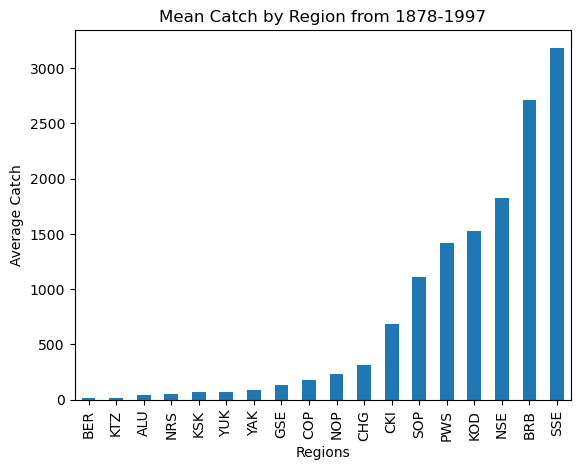

In [ ]:
avg_region.sort_values().plot(
    kind='bar',
    title='Mean Catch by Region from 1878-1997',
    xlabel='Regions',
    ylabel='Average Catch')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

The average catch from 1878 to 1997 differs significantly between regions in Alaska. Southern Southeast Alaska has the highest average catch, with 3184 reports of fish caught, whereas the Bering River Subarea only reports 16 fish caught. Interestingly the region reporting the second-highest catch, Bristol Bay Management Area, is geographically close to the three regions reporting the next-lowest catch (Kotzebue Management Area, Aleutian Islands Subarea, and Norton Sound Management Area) along the upper northwestern coast. This disparity makes me wonder if fishermen in northernmost regions of Alaska are all landing most of their catch at a port in the Bristol Bay Management Area. If I were to guess, this is likely due to lack of infrastructure or shipping resources in this part of the state. Annecdoteally, I know most salmon fishing in Alaska happens in the southeastern waters, which is supported by the data shown above.

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [170]:
grader.check_all()

q2a results: All test cases passed!

q2b results: All test cases passed!

q5 results: All test cases passed!

q7 results: All test cases passed!

q8 results: All test cases passed!